[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/08_clustering.ipynb)

*Machine Learning from Scratch · Notebook 8 of 10*

# Clustering & Unsupervised Learning

Finding structure without labels: k-means step by step, choosing k with the elbow and silhouette, hierarchical clustering, DBSCAN for odd shapes and noise, comparing clusterings, PCA, and distance-based outliers.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Clustering sorts a pile of items into groups with no labels, so it has no answer key to check against.

**What interviewers really test here:** k-means limits, choosing k, DBSCAN, and evaluating without labels.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Unsupervised learning and k-means *(Basics)*
- [ ] 2. k-means by hand *(Basics)*
- [ ] 3. How many clusters? *(Core)*
- [ ] 4. Hierarchical clustering *(Core)*
- [ ] 5. When k-means fails *(Core)*
- [ ] 6. Silhouette by hand *(Core)*
- [ ] 7. DBSCAN: density, shapes and noise *(Advanced)*
- [ ] 8. Evaluating clusters and reducing dimensions *(Advanced)*
- [ ] 9. Hierarchical clustering by hand *(Advanced)*
- [ ] 10. DBSCAN by hand, and choosing eps *(Advanced)*
- [ ] 11. Making clusters useful *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Clustering algorithms

| Algorithm | Needs k? | Shapes | Noise | Scale |
| --- | --- | --- | --- | --- |
| k-means | yes | round, similar size | no | very large (MiniBatchKMeans) |
| Gaussian mixture | yes | ellipses, soft assignments | no | medium |
| Agglomerative | yes (or a distance cut) | depends on linkage | no | O(n²) memory |
| DBSCAN / HDBSCAN | no (eps, min\_samples) | arbitrary | yes | large with an index |
| Mean shift | no (bandwidth) | blobs | no | small |
| Spectral | yes | non-convex, graphs | no | small–medium |

### k-means in detail

Objective: minimise inertia J = Σᵢ ‖xᵢ − μ\_{c(i)}‖². Lloyd's algorithm alternates assignment and centroid update; each step can only lower J, so it converges — but to a **local** minimum. k-means++ picks spread-out initial centres (each new centre chosen with probability ∝ squared distance to the nearest existing centre). Assumes spherical, equally sized clusters; sensitive to scale and outliers. Complexity O(n·k·d) per iteration.

### Cluster validation

| Score | Needs labels? | Meaning |
| --- | --- | --- |
| Inertia (elbow) | no | compactness; always falls with k |
| Silhouette | no | (b − a)/max(a, b), −1 … 1 |
| Davies–Bouldin | no | lower is better |
| Calinski–Harabasz | no | between/within dispersion, higher better |
| Rand / adjusted Rand | yes | pair agreement (ARI: 0 = chance, 1 = identical) |
| Normalised mutual information | yes | shared information, 0 … 1 |
| Homogeneity / completeness / V-measure | yes | each cluster one class / each class one cluster |

### Other unsupervised tasks

- **Dimensionality reduction**: PCA (linear, keeps variance), truncated SVD (sparse text), t-SNE / UMAP (visualisation), autoencoders.
- **Anomaly detection**: distance to k-th neighbour, Local Outlier Factor, Isolation Forest, One-class SVM, DBSCAN noise.
- **Association rules**: frequent itemsets (market baskets), support / confidence / lift.
- **Density estimation**: kernel density estimates, Gaussian mixtures.

---
# Part 2: Lessons, step by step

## Lesson 1: Unsupervised learning and k-means

*Level: Basics*

No labels this time — just data. **Clustering** groups similar rows: customer segments, document topics, image regions.



**k-means** finds k groups:




1. Pick k starting centres.
2. **Assign** each point to its nearest centre.
3. **Update** each centre to the mean of its points.
4. Repeat 2–3 until nothing changes.



It minimises **inertia** (sum of squared distances to centres). The result depends on the start, so sklearn runs several starts (`n_init`) with smart **k-means++** initialisation and keeps the best.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

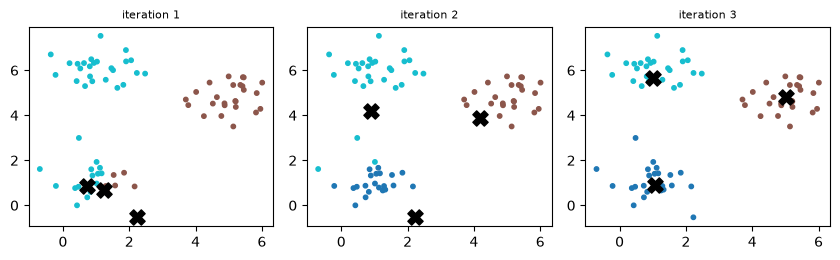

In [2]:
rng = np.random.default_rng(3)
BLOBS = np.vstack([rng.normal(c, 0.6, (25, 2)) for c in ([1, 1], [5, 5], [1, 6])])


def kmeans_steps():
    centers = BLOBS[[0, 1, 2]].copy()
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.7))
    for step, ax in enumerate(axes):
        d = ((BLOBS[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d.argmin(axis=1)
        ax.scatter(BLOBS[:, 0], BLOBS[:, 1], c=labels, cmap="tab10", s=10)
        ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=120, color="black")
        ax.set_title(f"iteration {step + 1}", fontsize=8)
        centers = np.array([BLOBS[labels == c].mean(axis=0) for c in range(3)])
    fig.tight_layout()


kmeans_steps()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q18](#q18), [Q3](#q3), [Q5](#q5), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 2: k-means by hand

*Level: Basics*

Six numbers on a line: 1, 2, 3, 10, 11, 12. Use k = 2 with a poor start: centres at 1 and 2.



| Round | Centres | Cluster A | Cluster B | New centres | Inertia |
| --- | --- | --- | --- | --- | --- |
| 1 | 1, 2 | 1 | 2, 3, 10, 11, 12 | 1, 7.6 | 89.2 |
| 2 | 1, 7.6 | 1, 2, 3 | 10, 11, 12 | 2, 11 | 4.0 |
| 3 | 2, 11 | 1, 2, 3 | 10, 11, 12 | 2, 11 | 4.0 (no change: stop) |



Check round 2: 3 is 2 from centre 1 and 4.6 from centre 7.6, so it joins A. Check the final inertia: each cluster contributes 1 + 0 + 1 = 2, for a total of 4.



#### Why it always stops



Assigning points to the nearest centre can only lower inertia, and so can moving a centre to the mean (the mean minimises squared distance). There are finitely many groupings, so it must stop.



But stopping isn't the same as finding the best answer. It only reaches a **local** minimum, so `n_init` runs it from several starts and keeps the lowest inertia.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def kmeans_by_hand():
    points = np.array([1.0, 2, 3, 10, 11, 12])
    centres = np.array([1.0, 2.0])
    history = []
    for round_number in range(4):
        labels = np.abs(points[:, None] - centres).argmin(axis=1)
        new_centres = np.array([points[labels == k].mean() for k in range(2)])
        inertia = ((points - new_centres[labels]) ** 2).sum()
        history.append((new_centres.tolist(), float(inertia)))
        if (new_centres == centres).all():
            break
        centres = new_centres


kmeans_by_hand()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q18](#q18), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: How many clusters?

*Level: Core*

k-means needs k up front. Two common guides:




- **Elbow**: plot inertia against k. It always falls; look for the bend where adding clusters stops helping much.
- **Silhouette**: for each point, a = mean distance to its own cluster, b = mean distance to the nearest other cluster; s = (b − a)/max(a, b). Near 1 = well placed, near 0 = on a border, negative = probably in the wrong cluster. Pick the k with the highest average.



Domain knowledge matters too — "three customer tiers" may be the useful answer even if the math prefers four.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

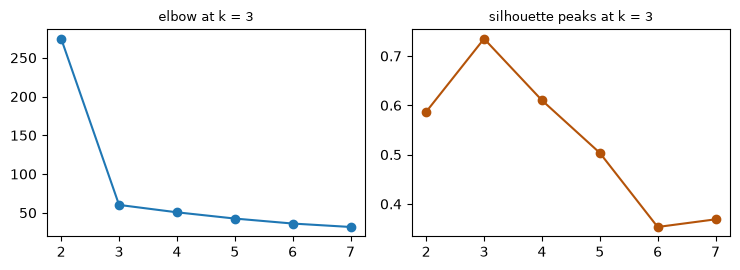

In [4]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(3)
BLOBS = np.vstack([rng.normal(c, 0.6, (25, 2)) for c in ([1, 1], [5, 5], [1, 6])])


def elbow_silhouette():
    ks = range(2, 8)
    inertias, sils = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=5, random_state=0).fit(BLOBS)
        inertias.append(km.inertia_)
        sils.append(silhouette_score(BLOBS, km.labels_))
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    left.plot(list(ks), inertias, "o-")
    left.set_title("elbow at k = 3", fontsize=9)
    right.plot(list(ks), sils, "o-", color="#b45309")
    right.set_title("silhouette peaks at k = 3", fontsize=9)
    fig.tight_layout()


elbow_silhouette()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q6](#q6), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Hierarchical clustering

*Level: Core*

Start with every point as its own cluster and repeatedly **merge the two closest clusters**. The merge history forms a tree (a **dendrogram**); cut it at any level to get that many clusters. "Closest" is the **linkage**:



| Linkage | Distance between clusters | Behaviour |
| --- | --- | --- |
| single | closest pair of members | follows chains, odd shapes; sensitive to noise |
| complete | farthest pair | compact clusters |
| average | mean of all pairs | in between |
| ward | increase in within-cluster SSE | like k-means; the default |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

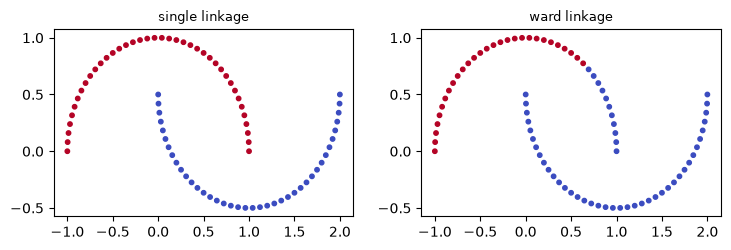

In [5]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering


def moons_linkage():
    t = np.linspace(0, np.pi, 40)
    moons = np.vstack([np.column_stack([np.cos(t), np.sin(t)]), np.column_stack([1 - np.cos(t), 0.5 - np.sin(t)])])
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6))
    for ax, link in zip(axes, ["single", "ward"]):
        labels = AgglomerativeClustering(n_clusters=2, linkage=link).fit_predict(moons)
        ax.scatter(moons[:, 0], moons[:, 1], c=labels, cmap="coolwarm", s=10)
        ax.set_title(f"{link} linkage", fontsize=9)
    fig.tight_layout()


moons_linkage()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 5: When k-means fails

*Level: Core*

k-means assumes round, similar-sized clusters, because each point simply joins its nearest centre. The boundary between two centres is always a straight line.



| Data | What goes wrong | Try |
| --- | --- | --- |
| Stretched clusters | cuts across them | Gaussian mixture, or rescale |
| Rings or moons | can't follow shapes | DBSCAN, spectral clustering |
| A small cluster beside a large one | splits the large one | Gaussian mixture, DBSCAN |
| Features on different scales | the largest feature decides everything | standardise first |
| Outliers | drag the means away | remove them first, k-medoids, DBSCAN |



#### k-means++



Starting centres matter. k-means++ chooses the first at random, then picks each next one with probability proportional to its **squared distance** from the nearest centre already chosen. This spreads them out, and it's sklearn's default.



#### Soft clustering



A **Gaussian mixture** treats each cluster as a bell curve with its own shape, and gives probabilities: "70% cluster A, 30% cluster B".

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

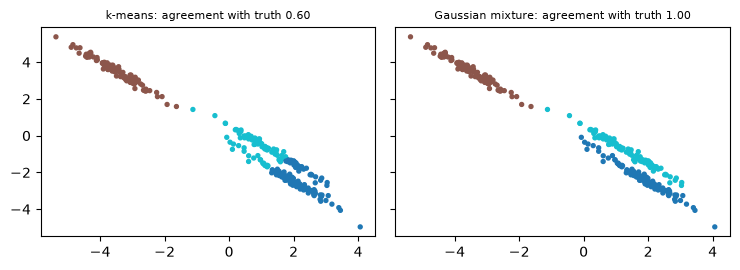

In [6]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering


def kmeans_failures():
    from sklearn.mixture import GaussianMixture
    from sklearn.metrics import adjusted_rand_score
    r = np.random.default_rng(0)
    centres = np.array([[-2.4, 1.2], [0, -2.4], [2.4, 1.2]])
    round_blobs = np.vstack([r.normal(c, 0.6, (100, 2)) for c in centres])
    stretched = round_blobs @ np.array([[1, -0.9], [-0.8, 1]])
    truth = np.repeat([0, 1, 2], 100)
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8), sharey=True)
    models = [("k-means", KMeans(n_clusters=3, n_init=5, random_state=0)), ("Gaussian mixture", GaussianMixture(n_components=3, random_state=0))]
    for ax, (name, model) in zip(axes, models):
        labels = model.fit_predict(stretched)
        ax.scatter(stretched[:, 0], stretched[:, 1], c=labels, cmap="tab10", s=8)
        ax.set_title(f"{name}: agreement with truth {adjusted_rand_score(truth, labels):.2f}", fontsize=8)
    fig.tight_layout()


kmeans_failures()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q4](#q4), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 6: Silhouette by hand

*Level: Core*

Clusters {1, 2, 3} and {10, 11, 12}. Calculate the silhouette for two points.



#### Point 1



- a = mean distance to its own cluster: (1 + 2) / 2 = 1.5
- b = mean distance to the other cluster: (9 + 10 + 11) / 3 = 10
- s = (10 − 1.5) / 10 = **0.85**



#### Point 3 (nearer the other cluster)



- a = (2 + 1) / 2 = 1.5
- b = (7 + 8 + 9) / 3 = 8
- s = (8 − 1.5) / 8 = **0.8125**



| s | Meaning |
| --- | --- |
| Near 1 | tight, well separated |
| Near 0 | on the border between clusters |
| Negative | closer to another cluster: possibly misplaced |



Inertia always falls as k grows, so it can't choose k alone. Silhouette can go up or down, so it can. The average can hide a poor cluster, so a **silhouette plot** (one bar per point) shows each cluster separately.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

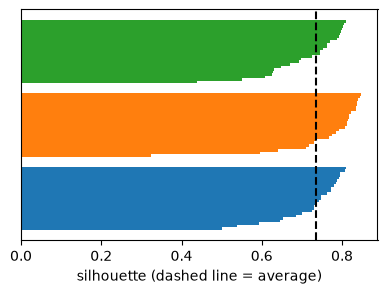

In [7]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
rng = np.random.default_rng(3)
BLOBS = np.vstack([rng.normal(c, 0.6, (25, 2)) for c in ([1, 1], [5, 5], [1, 6])])


def silhouette_plot():
    from sklearn.metrics import silhouette_samples
    labels = KMeans(n_clusters=3, n_init=5, random_state=0).fit_predict(BLOBS)
    values = silhouette_samples(BLOBS, labels)
    fig, ax = plt.subplots(figsize=(4.6, 3))
    y = 0
    for c in range(3):
        part = np.sort(values[labels == c])
        ax.barh(np.arange(y, y + len(part)), part, height=1)
        y += len(part) + 4
    ax.axvline(values.mean(), ls="--", color="black")
    ax.set_xlabel("silhouette (dashed line = average)")
    ax.set_yticks([])


silhouette_plot()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q6](#q6), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 7: DBSCAN: density, shapes and noise

*Level: Advanced*

**DBSCAN** defines clusters as dense regions:




- A **core point** has at least min\_samples points within distance eps.
- Clusters grow from core points through their neighbours; border points join but don't spread it further.
- Points reachable from no core point are **noise** (label −1) — built-in outlier detection.



No need to choose k, finds any shape, but struggles when clusters have very different densities. Choose eps from a "k-distance plot" (distance to each point's k-th neighbour, sorted — look for the knee).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

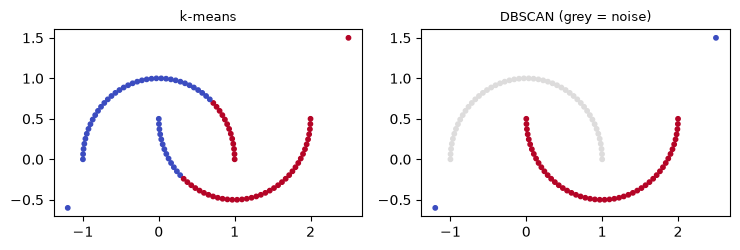

In [8]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering


def dbscan_vs_kmeans():
    t = np.linspace(0, np.pi, 50)
    moons = np.vstack([np.column_stack([np.cos(t), np.sin(t)]), np.column_stack([1 - np.cos(t), 0.5 - np.sin(t)]), [[2.5, 1.5], [-1.2, -0.6]]])
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6))
    for ax, (name, model) in zip(axes, [("k-means", KMeans(n_clusters=2, n_init=5, random_state=0)), ("DBSCAN", DBSCAN(eps=0.25, min_samples=3))]):
        labels = model.fit_predict(moons)
        ax.scatter(moons[:, 0], moons[:, 1], c=labels, cmap="coolwarm", s=10)
        ax.set_title(f"{name}" + (" (grey = noise)" if name == "DBSCAN" else ""), fontsize=9)
    fig.tight_layout()


dbscan_vs_kmeans()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q13](#q13), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 8: Evaluating clusters and reducing dimensions

*Level: Advanced*

Without labels, use internal scores (silhouette, Davies–Bouldin). If true classes exist for a sample, compare with external scores: a **contingency table**, the **Rand index** (share of point pairs treated the same way; the adjusted version corrects for chance), homogeneity and completeness. Cluster numbers are arbitrary — only the grouping matters.



**PCA** (from the math course) is the other classic unsupervised tool: compress many correlated features into a few components, often before clustering or to plot data in 2-D. t-SNE and UMAP make prettier 2-D maps but distort distances.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

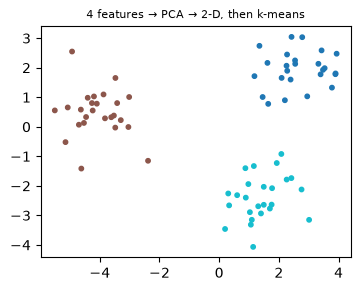

In [9]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
rng = np.random.default_rng(3)
BLOBS = np.vstack([rng.normal(c, 0.6, (25, 2)) for c in ([1, 1], [5, 5], [1, 6])])


def pca_then_cluster():
    from sklearn.decomposition import PCA
    data = np.hstack([BLOBS, BLOBS @ np.array([[0.5, 0.2], [0.1, 0.7]]) + rng.normal(0, 0.1, BLOBS.shape)])
    reduced = PCA(n_components=2).fit_transform(data)
    labels = KMeans(n_clusters=3, n_init=5, random_state=0).fit_predict(reduced)
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap="tab10", s=10)
    ax.set_title("4 features → PCA → 2-D, then k-means", fontsize=8)


pca_then_cluster()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q7](#q7), [Q15](#q15), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 9: Hierarchical clustering by hand

*Level: Advanced*

Five points: 1, 2, 4, 8, 9. Start with each alone, and merge the closest pair each time.



| Step | Single linkage merges | At distance | Complete linkage merges | At distance |
| --- | --- | --- | --- | --- |
| 1 | {1} + {2} | 1 | {1} + {2} | 1 |
| 2 | {8} + {9} | 1 | {8} + {9} | 1 |
| 3 | {1, 2} + {4} | 2 (from 2 to 4) | {1, 2} + {4} | 3 (from 1 to 4) |
| 4 | {1, 2, 4} + {8, 9} | 4 (from 4 to 8) | {1, 2, 4} + {8, 9} | 8 (from 1 to 9) |



#### Reading a dendrogram



The height of each join is the distance at which clusters merged. **To choose clusters, cut horizontally across a large gap.** Here the jump from 2 to 4 under single linkage suggests two clusters: {1, 2, 4} and {8, 9}.



You don't need to decide k in advance, and the tree shows structure at every level. But it needs O(n²) memory and merges can never be undone.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

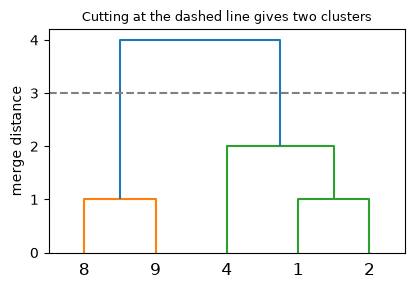

In [10]:
def dendrogram_demo():
    from scipy.cluster.hierarchy import dendrogram, linkage
    points = np.array([[1.0], [2.0], [4.0], [8.0], [9.0]])
    merges = linkage(points, method="single")
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    dendrogram(merges, labels=["1", "2", "4", "8", "9"], ax=ax)
    ax.axhline(3, ls="--", color="gray")
    ax.set_ylabel("merge distance")
    ax.set_title("Cutting at the dashed line gives two clusters", fontsize=9)


dendrogram_demo()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 10: DBSCAN by hand, and choosing eps

*Level: Advanced*

Points: 1, 1.5, 2, 2.2, 8, 8.3, 8.5, 15, with eps = 0.6 and min\_samples = 3 (counting the point itself).



| Point | Within 0.6 | Count | Type | Result |
| --- | --- | --- | --- | --- |
| 1 | 1, 1.5 | 2 | border | cluster 0 |
| 1.5 | 1, 1.5, 2 | 3 | core | cluster 0 |
| 2 | 1.5, 2, 2.2 | 3 | core | cluster 0 |
| 2.2 | 2, 2.2 | 2 | border | cluster 0 |
| 8, 8.3, 8.5 | all three | 3 | core | cluster 1 |
| 15 | 15 | 1 | noise | −1 |



Clusters spread only through core points. Point 1 joins because it's within reach of core point 1.5, but it can't extend the cluster further.



#### Choosing the settings



1. min\_samples: start at about 2 × the number of features.
2. For each point, find the distance to its (min\_samples)-th neighbour, then sort and plot these.
3. Look for the **knee**: dense points sit on the flat part, and noise on the steep part. Set eps at the knee.



Always scale features first, since eps is a single distance applied to all of them.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

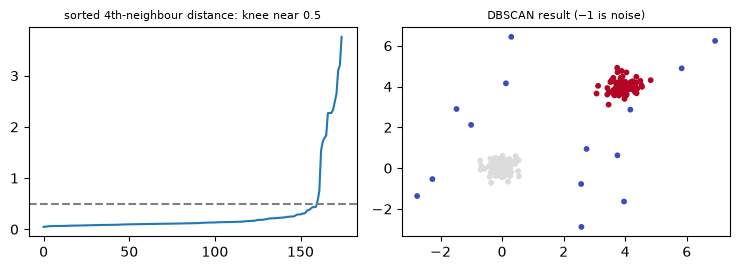

In [11]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering


def k_distance_plot():
    from sklearn.neighbors import NearestNeighbors
    r = np.random.default_rng(0)
    data = np.vstack([r.normal([0, 0], 0.3, (80, 2)), r.normal([4, 4], 0.3, (80, 2)), r.uniform(-3, 7, (15, 2))])
    distances, _ = NearestNeighbors(n_neighbors=4).fit(data).kneighbors(data)
    curve = np.sort(distances[:, 3])
    labels = DBSCAN(eps=0.5, min_samples=4).fit_predict(data)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    left.plot(curve)
    left.axhline(0.5, ls="--", color="gray")
    left.set_title("sorted 4th-neighbour distance: knee near 0.5", fontsize=8)
    right.scatter(data[:, 0], data[:, 1], c=labels, cmap="coolwarm", s=10)
    right.set_title("DBSCAN result (−1 is noise)", fontsize=8)
    fig.tight_layout()


k_distance_plot()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q13](#q13), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 11: Making clusters useful

*Level: Advanced*

A clustering score doesn't tell you whether clusters mean anything. A real project continues with:



1. **Profile them:** compare each cluster's feature averages with the overall average.
2. **Name them:** "young, frequent, low spend" is something a team can act on.
3. **Test stability:** rerun with other seeds or a sample of the data. Do the same groups come back?
4. **Link to action:** do the groups differ in an outcome that matters, such as churn?



#### Common mistakes



- Clustering unscaled data, or data with many irrelevant features.
- Believing clusters exist because an algorithm returned them. k-means always returns k groups, **even for pure noise**.
- Reading meaning into a t-SNE or UMAP plot's cluster sizes or the distances between them.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

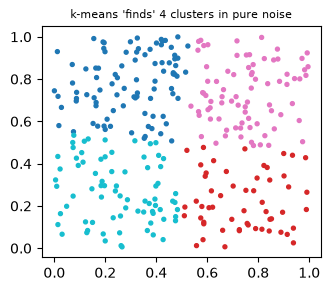

In [12]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering


def cluster_profile():
    r = np.random.default_rng(0)
    df = pd.DataFrame({"age": np.r_[r.normal(25, 3, 50), r.normal(55, 5, 50)], "spend": np.r_[r.normal(200, 40, 50), r.normal(900, 100, 50)]})
    scaled = (df - df.mean()) / df.std()
    df["cluster"] = KMeans(n_clusters=2, n_init=5, random_state=0).fit_predict(scaled)
    profile = df.groupby("cluster").mean().round(1)
    sizes = df["cluster"].value_counts().sort_index()
    noise = r.uniform(size=(300, 2))
    noise_labels = KMeans(n_clusters=4, n_init=5, random_state=0).fit_predict(noise)
    fig, ax = plt.subplots(figsize=(3.6, 3))
    ax.scatter(noise[:, 0], noise[:, 1], c=noise_labels, cmap="tab10", s=8)
    ax.set_title("k-means 'finds' 4 clusters in pure noise", fontsize=8)


cluster_profile()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q7](#q7). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [13]:
from sklearn.metrics import pairwise_distances_argmin, silhouette_score, silhouette_samples, rand_score

import math

from sklearn.neighbors import NearestCentroid, NearestNeighbors

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

from sklearn.decomposition import PCA


<a id="q1"></a>
### Q1. Assign Points to the Nearest Centre

🟢 Warm-up · *k-means step 1*

Return the index of the closest centre for every point.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], centers = [[1, 1], [2, 1.2], [8, 8]]` → `[0, 1, 1, 2, 2, 2, 1, 2, 2]`

In [ ]:
def assign(X, centers):
    """
    Return the index of the closest centre for every point.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(assign, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [2, 1.2], [8, 8]]), [0, 1, 1, 2, 2, 2, 1, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Distance to each centre, keep the smallest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`pairwise_distances_argmin(X, centers)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Distance to each centre, keep the smallest.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))


def assign(X, centers):
    return [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
```

**Cost:** O(n·k·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `pairwise_distances_argmin(X, centers)`.

```python
def assign(X, centers):
    return pairwise_distances_argmin(X, centers)
```

**Cost:** O(n·k·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Distance to each centre, keep the smallest. That costs O(n·k·d) time and O(n) space."

"I can do better: `pairwise_distances_argmin(X, centers)`. That's O(n·k·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/assign-points-to-the-nearest-centre)

<a id="q2"></a>
### Q2. Move Each Centre to Its Points' Mean

🟢 Warm-up · *k-means step 2*

Given cluster labels, return each cluster's centroid (clusters 0, 1, …), rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], labels = [0, 0, 0, 1, 1, 1, 2, 2, 2]` → `[[1.5, 1.4], [8.5, 8.4], [1.5, 8.5]]`

In [ ]:
def centroids(X, labels):
    """
    Given cluster labels, return each cluster's centroid (clusters 0, 1, …),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(centroids, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [0, 0, 0, 1, 1, 1, 2, 2, 2]), [[1.5, 1.4], [8.5, 8.4], [1.5, 8.5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average the points in each cluster.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`NearestCentroid().fit(X, labels).centroids_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average the points in each cluster.

```python
def centroids(X, labels):
    out = []
    for c in sorted(set(labels)):
        members = [p for p, lab in zip(X, labels) if lab == c]
        out.append([round(sum(col) / len(members), 4) for col in zip(*members)])
    return out
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `NearestCentroid().fit(X, labels).centroids_`.

```python
def centroids(X, labels):
    return NearestCentroid().fit(X, labels).centroids_.round(4)
```

**Cost:** O(n·d) time, O(k·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average the points in each cluster. That costs O(n·d) time and O(k·d) space."

"I can do better: `NearestCentroid().fit(X, labels).centroids_`. That's O(n·d) time and O(k·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/move-each-centre-to-its-points-mean)

<a id="q3"></a>
### Q3. Inertia

🟢 Warm-up · *Within-cluster sum of squares*

After running k-means from the given centres, return the total squared distance of every point to its centre, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [2, 1.2], [8, 8]]` → `3.12`
- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [8, 8], [1, 8]]` → `3.12`

In [ ]:
def inertia(X, init):
    """
    After running k-means from the given centres, return the total squared
    distance of every point to its centre, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(inertia, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [2, 1.2], [8, 8]]), 3.12),
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [8, 8], [1, 8]]), 3.12),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run the from-scratch k-means, then add up squared distances.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KMeans(...).inertia_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Run the from-scratch k-means, then add up squared distances.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def inertia(X, init):
    labels, centers = kmeans_scratch(X, [list(map(float, c)) for c in init])
    return round(sum(dist(p, centers[lab]) ** 2 for p, lab in zip(X, labels)), 4)
```

**Cost:** O(iters·n·k·d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KMeans(...).inertia_`.

```python
def inertia(X, init):
    return round(KMeans(n_clusters=len(init), init=np.array(init, dtype=float), n_init=1).fit(X).inertia_, 4)
```

**Cost:** O(iters·n·k·d) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run the from-scratch k-means, then add up squared distances. That costs O(iters·n·k·d) time and O(1) space."

"I can do better: `KMeans(...).inertia_`. That's O(iters·n·k·d) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/inertia)

<a id="q4"></a>
### Q4. Cluster Sizes

🟢 Warm-up · *How many points in each cluster?*

Run k-means from the given starting centres and return how many points end up in each cluster.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [2, 1.2], [8, 8]]` → `[3, 3, 3]`

In [ ]:
def cluster_sizes(X, init):
    """
    Run k-means from the given starting centres and return how many points end
    up in each cluster.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cluster_sizes, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [2, 1.2], [8, 8]]), [3, 3, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count the from-scratch k-means labels.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.bincount(km.labels_)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count the from-scratch k-means labels.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def cluster_sizes(X, init):
    labels, _ = kmeans_scratch(X, [list(map(float, c)) for c in init])
    return [labels.count(c) for c in range(len(init))]
```

**Cost:** O(iters·n·k·d) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.bincount(km.labels_)`.

```python
def cluster_sizes(X, init):
    km = KMeans(n_clusters=len(init), init=np.array(init, dtype=float), n_init=1).fit(X)
    return np.bincount(km.labels_, minlength=len(init))
```

**Cost:** O(iters·n·k·d) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count the from-scratch k-means labels. That costs O(iters·n·k·d) time and O(k) space."

"I can do better: `np.bincount(km.labels_)`. That's O(iters·n·k·d) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/cluster-sizes)

<a id="q5"></a>
### Q5. Predict the Cluster of New Points

🟢 Warm-up · *Using a fitted k-means*

Fit k-means from INIT-style starting centres, then return the cluster of each new point.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [8, 8], [1, 8]], X_new = [[0, 0], [7, 9], [3, 7]]` → `[0, 1, 2]`

In [ ]:
def predict_cluster(X, init, X_new):
    """
    Fit k-means from INIT-style starting centres, then return the cluster of
    each new point.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predict_cluster, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [8, 8], [1, 8]], [[0, 0], [7, 9], [3, 7]]), [0, 1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run k-means, then nearest-centre assignment for the new points.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`km.predict(X_new)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Run k-means, then nearest-centre assignment for the new points.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def predict_cluster(X, init, X_new):
    labels, centers = kmeans_scratch(X, [list(map(float, c)) for c in init])
    return [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X_new]
```

**Cost:** O(iters·n·k·d) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `km.predict(X_new)`.

```python
def predict_cluster(X, init, X_new):
    return KMeans(n_clusters=len(init), init=np.array(init, dtype=float), n_init=1).fit(X).predict(X_new)
```

**Cost:** O(iters·n·k·d) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run k-means, then nearest-centre assignment for the new points. That costs O(iters·n·k·d) time and O(m) space."

"I can do better: `km.predict(X_new)`. That's O(iters·n·k·d) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/predict-the-cluster-of-new-points)

<a id="q6"></a>
### Q6. Silhouette Score

🟢 Warm-up · *One number for cluster quality*

Return the mean silhouette over all points, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], labels = [0, 0, 0, 1, 1, 1, 2, 2, 2]` → `0.8558`
- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], labels = [0, 0, 0, 1, 1, 1, 1, 1, 1]` → `0.5878`

In [ ]:
def silhouette_mean(X, labels):
    """
    Return the mean silhouette over all points, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(silhouette_mean, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [0, 0, 0, 1, 1, 1, 2, 2, 2]), 0.8558),
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [0, 0, 0, 1, 1, 1, 1, 1, 1]), 0.5878),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average the per-point silhouettes computed by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`silhouette_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Average the per-point silhouettes computed by hand.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))


def silhouette_mean(X, labels):
    total = 0
    for i, p in enumerate(X):
        same = [dist(p, q) for j, q in enumerate(X) if labels[j] == labels[i] and j != i]
        a = sum(same) / len(same)
        b = min(sum(dist(p, q) for j, q in enumerate(X) if labels[j] == c) / labels.count(c)
                for c in set(labels) if c != labels[i])
        total += (b - a) / max(a, b)
    return round(total / len(X), 4)
```

**Cost:** O(n²·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `silhouette_score`.

```python
def silhouette_mean(X, labels):
    return round(silhouette_score(X, labels), 4)
```

**Cost:** O(n²·d) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average the per-point silhouettes computed by hand. That costs O(n²·d) time and O(n) space."

"I can do better: `silhouette_score`. That's O(n²·d) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/silhouette-score)

<a id="q7"></a>
### Q7. Contingency Table

🟢 Warm-up · *True classes vs found clusters*

Return a table whose row i, column j counts points with class i (sorted) in cluster j (sorted).

**Examples**

- `classes = ['a', 'a', 'b', 'b', 'b', 'c'], clusters = [0, 0, 1, 1, 0, 2]` → `[[2, 0, 0], [1, 2, 0], [0, 0, 1]]`

In [ ]:
from sklearn.metrics.cluster import contingency_matrix

def contingency(classes, clusters):
    """
    Return a table whose row i, column j counts points with class i (sorted) in
    cluster j (sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(contingency, [
    ((['a', 'a', 'b', 'b', 'b', 'c'], [0, 0, 1, 1, 0, 2]), [[2, 0, 0], [1, 2, 0], [0, 0, 1]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested counting.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`contingency_matrix(classes, clusters)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Nested counting.

```python
def contingency(classes, clusters):
    rows, cols = sorted(set(classes)), sorted(set(clusters))
    return [[sum(1 for a, b in zip(classes, clusters) if a == r and b == c) for c in cols] for r in rows]
```

**Cost:** O(n·r·c) time, O(r·c) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `contingency_matrix(classes, clusters)`.

```python
def contingency(classes, clusters):
    return contingency_matrix(classes, clusters)
```

**Cost:** O(n) time, O(r·c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested counting. That costs O(n·r·c) time and O(r·c) space."

"I can do better: `contingency_matrix(classes, clusters)`. That's O(n) time and O(r·c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/contingency-table)

<a id="q8"></a>
### Q8. The Elbow Curve

🟡 Interview standard · *Inertia for k = 1 … K*

For k = 1 … max\_k, start k-means from the first k points and return the final inertia of each, rounded to 1 decimal.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], max_k = 4` → `[200.5, 76.6, 76.0, 2.5]`

In [ ]:
def elbow(X, max_k):
    """
    For k = 1 … max_k, start k-means from the first k points and return the
    final inertia of each, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(elbow, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], 4), [200.5, 76.6, 76.0, 2.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The from-scratch k-means for each k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A `KMeans` per k.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The from-scratch k-means for each k.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def elbow(X, max_k):
    out = []
    for k in range(1, max_k + 1):
        labels, centers = kmeans_scratch(X, [list(map(float, p)) for p in X[:k]])
        out.append(round(sum(dist(p, centers[lab]) ** 2 for p, lab in zip(X, labels)), 1))
    return out
```

**Cost:** O(K·iters·n·k·d) time, O(K) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A `KMeans` per k.

```python
def elbow(X, max_k):
    A = np.array(X, dtype=float)
    return [round(KMeans(n_clusters=k, init=A[:k], n_init=1).fit(A).inertia_, 1) for k in range(1, max_k + 1)]
```

**Cost:** O(K·iters·n·k·d) time, O(K) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The from-scratch k-means for each k. That costs O(K·iters·n·k·d) time and O(K) space."

"I can do better: A `KMeans` per k. That's O(K·iters·n·k·d) time and O(K) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/the-elbow-curve)

<a id="q9"></a>
### Q9. Silhouette of Each Point

🟡 Interview standard · *(b − a) / max(a, b)*

a = mean distance to the other points in its cluster; b = mean distance to the nearest other cluster. Return each point's silhouette, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [1, 2], [5, 5], [6, 5], [5, 6]], labels = [0, 0, 1, 1, 1]` → `[0.8375, 0.818, 0.8123, 0.8027, 0.7998]`

In [ ]:
def silhouettes(X, labels):
    """
    a = mean distance to the other points in its cluster; b = mean distance to
    the nearest other cluster. Return each point's silhouette, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(silhouettes, [
    (([[1, 1], [1, 2], [5, 5], [6, 5], [5, 6]], [0, 0, 1, 1, 1]), [0.8375, 0.818, 0.8123, 0.8027, 0.7998]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute a and b for every point with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`silhouette_samples(X, labels)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute a and b for every point with loops.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))


def silhouettes(X, labels):
    out = []
    for i, p in enumerate(X):
        same = [dist(p, q) for j, q in enumerate(X) if labels[j] == labels[i] and j != i]
        a = sum(same) / len(same) if same else 0.0
        b = min(sum(dist(p, q) for j, q in enumerate(X) if labels[j] == c) / labels.count(c)
                for c in set(labels) if c != labels[i])
        out.append(round((b - a) / max(a, b), 4) if same else 0.0)
    return out
```

**Cost:** O(n²·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `silhouette_samples(X, labels)`.

```python
def silhouettes(X, labels):
    return silhouette_samples(X, labels).round(4)
```

**Cost:** O(n²·d) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute a and b for every point with loops. That costs O(n²·d) time and O(n) space."

"I can do better: `silhouette_samples(X, labels)`. That's O(n²·d) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/silhouette-of-each-point)

<a id="q10"></a>
### Q10. Choose k by Silhouette

🟡 Interview standard · *Best number of clusters*

For k = 2 … max\_k, run k-means from the first k points and return the k with the highest silhouette score.

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], max_k = 4` → `4`

In [ ]:
def best_k(X, max_k):
    """
    For k = 2 … max_k, run k-means from the first k points and return the k with
    the highest silhouette score.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_k, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], 4), 4),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

From-scratch k-means and silhouette for each k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KMeans` + `silhouette_score` per k.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** From-scratch k-means and silhouette for each k.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def best_k(X, max_k):
    best = (None, -2)
    for k in range(2, max_k + 1):
        labels, _ = kmeans_scratch(X, [list(map(float, p)) for p in X[:k]])
        total = 0
        for i, p in enumerate(X):
            same = [dist(p, q) for j, q in enumerate(X) if labels[j] == labels[i] and j != i]
            if not same:
                continue
            a = sum(same) / len(same)
            b = min(sum(dist(p, q) for j, q in enumerate(X) if labels[j] == c) / labels.count(c)
                    for c in set(labels) if c != labels[i])
            total += (b - a) / max(a, b)
        if total / len(X) > best[1]:
            best = (k, total / len(X))
    return best[0]
```

**Cost:** O(K·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KMeans` + `silhouette_score` per k.

```python
def best_k(X, max_k):
    A = np.array(X, dtype=float)
    scores = [silhouette_score(A, KMeans(n_clusters=k, init=A[:k], n_init=1).fit_predict(A)) for k in range(2, max_k + 1)]
    return 2 + int(np.argmax(scores))
```

**Cost:** O(K·n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: From-scratch k-means and silhouette for each k. That costs O(K·n²) time and O(n) space."

"I can do better: `KMeans` + `silhouette_score` per k. That's O(K·n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/choose-k-by-silhouette)

<a id="q11"></a>
### Q11. Hierarchical Clustering: Single Linkage

🟡 Interview standard · *Merge the closest pair of points*

Start with every point alone and repeatedly merge the two clusters whose closest members are nearest, until n\_clusters remain. Return labels numbered in order of first appearance.

**Examples**

- `X = [[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], n_clusters = 3` → `[0, 0, 0, 0, 1, 1, 2, 2]`
- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], n_clusters = 3` → `[0, 0, 0, 1, 1, 1, 2, 2, 2]`

In [ ]:
def single_link(X, n_clusters):
    """
    Start with every point alone and repeatedly merge the two clusters whose
    closest members are nearest, until n_clusters remain. Return labels numbered
    in order of first appearance.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(single_link, [
    (([[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], 3), [0, 0, 0, 0, 1, 1, 2, 2]),
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], 3), [0, 0, 0, 1, 1, 1, 2, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Naive agglomeration: compute all cluster gaps each round, merge the smallest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`AgglomerativeClustering(n_clusters, linkage='single')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Naive agglomeration: compute all cluster gaps each round, merge the smallest.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out

def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def agglomerate(X, n_clusters, linkage):
    clusters = [[i] for i in range(len(X))]

    def gap(A, B):
        ds = [dist(X[i], X[j]) for i in A for j in B]
        if linkage == "single":
            return min(ds)
        if linkage == "complete":
            return max(ds)
        if linkage == "average":
            return sum(ds) / len(ds)
        def sse(idx):
            m = [sum(X[i][d] for i in idx) / len(idx) for d in range(len(X[0]))]
            return sum(dist(X[i], m) ** 2 for i in idx)
        return sse(A + B) - sse(A) - sse(B)

    while len(clusters) > n_clusters:
        a, b = min(((i, j) for i in range(len(clusters)) for j in range(i + 1, len(clusters))),
                   key=lambda ij: gap(clusters[ij[0]], clusters[ij[1]]))
        clusters[a] = clusters[a] + clusters[b]
        del clusters[b]
    labels = [0] * len(X)
    for c, members in enumerate(clusters):
        for i in members:
            labels[i] = c
    return canon(labels)


def single_link(X, n_clusters):
    return agglomerate(X, n_clusters, "single")
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `AgglomerativeClustering(n_clusters, linkage='single')`.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out


def single_link(X, n_clusters):
    return canon(AgglomerativeClustering(n_clusters=n_clusters, linkage="single").fit_predict(X))
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Naive agglomeration: compute all cluster gaps each round, merge the smallest. That costs O(n³) time and O(n) space."

"I can do better: `AgglomerativeClustering(n_clusters, linkage='single')`. That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/hierarchical-clustering-single-linkage)

<a id="q12"></a>
### Q12. Hierarchical Clustering: Complete Linkage

🟡 Interview standard · *Merge by the farthest members*

Same, but the gap between clusters is the distance between their farthest members.

**Examples**

- `X = [[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], n_clusters = 3` → `[0, 0, 0, 0, 1, 1, 2, 2]`

In [ ]:
def complete_link(X, n_clusters):
    """
    Same, but the gap between clusters is the distance between their farthest
    members.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(complete_link, [
    (([[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], 3), [0, 0, 0, 0, 1, 1, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Naive agglomeration with max instead of min.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`linkage='complete'`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Naive agglomeration with max instead of min.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out

def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def agglomerate(X, n_clusters, linkage):
    clusters = [[i] for i in range(len(X))]

    def gap(A, B):
        ds = [dist(X[i], X[j]) for i in A for j in B]
        if linkage == "single":
            return min(ds)
        if linkage == "complete":
            return max(ds)
        if linkage == "average":
            return sum(ds) / len(ds)
        def sse(idx):
            m = [sum(X[i][d] for i in idx) / len(idx) for d in range(len(X[0]))]
            return sum(dist(X[i], m) ** 2 for i in idx)
        return sse(A + B) - sse(A) - sse(B)

    while len(clusters) > n_clusters:
        a, b = min(((i, j) for i in range(len(clusters)) for j in range(i + 1, len(clusters))),
                   key=lambda ij: gap(clusters[ij[0]], clusters[ij[1]]))
        clusters[a] = clusters[a] + clusters[b]
        del clusters[b]
    labels = [0] * len(X)
    for c, members in enumerate(clusters):
        for i in members:
            labels[i] = c
    return canon(labels)


def complete_link(X, n_clusters):
    return agglomerate(X, n_clusters, "complete")
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `linkage='complete'`.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out


def complete_link(X, n_clusters):
    return canon(AgglomerativeClustering(n_clusters=n_clusters, linkage="complete").fit_predict(X))
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Naive agglomeration with max instead of min. That costs O(n³) time and O(n) space."

"I can do better: `linkage='complete'`. That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/hierarchical-clustering-complete-linkage)

<a id="q13"></a>
### Q13. DBSCAN Core Points

🟡 Interview standard · *Who has enough neighbours?*

Return the indices of the core points.

**Examples**

- `X = [[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], eps = 0.5, min_samples = 3` → `[0, 1, 2, 3, 4, 5, 6, 7]`
- `X = [[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], eps = 0.5, min_samples = 5` → `[]`

In [ ]:
def core_points(X, eps, min_samples):
    """
    Return the indices of the core points.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(core_points, [
    (([[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], 0.5, 3), [0, 1, 2, 3, 4, 5, 6, 7]),
    (([[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], 0.5, 5), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each point's neighbours within eps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DBSCAN(...).fit(X).core_sample_indices_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count each point's neighbours within eps.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def dbscan_scratch(X, eps, min_samples):
    n = len(X)
    neighbours = [[j for j in range(n) if dist(X[i], X[j]) <= eps] for i in range(n)]
    core = [len(nb) >= min_samples for nb in neighbours]
    labels = [-1] * n
    cluster = 0
    for i in range(n):
        if not core[i] or labels[i] != -1:
            continue
        stack = [i]
        labels[i] = cluster
        while stack:
            p = stack.pop()
            if not core[p]:
                continue
            for q in neighbours[p]:
                if labels[q] == -1:
                    labels[q] = cluster
                    stack.append(q)
        cluster += 1
    return labels, [i for i in range(n) if core[i]]


def core_points(X, eps, min_samples):
    return dbscan_scratch(X, eps, min_samples)[1]
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DBSCAN(...).fit(X).core_sample_indices_`.

```python
def core_points(X, eps, min_samples):
    return DBSCAN(eps=eps, min_samples=min_samples).fit(X).core_sample_indices_
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each point's neighbours within eps. That costs O(n²) time and O(n) space."

"I can do better: `DBSCAN(...).fit(X).core_sample_indices_`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/dbscan-core-points)

<a id="q14"></a>
### Q14. Rand Index

🟡 Interview standard · *Do two clusterings agree?*

Return the share of point pairs on which two labelings agree (both same cluster, or both different), rounded to 4 decimals.

**Examples**

- `a = [0, 0, 1, 1, 2, 2], b = [1, 1, 0, 0, 0, 2]` → `0.8`
- `a = [0, 0, 1], b = [5, 5, 7]` → `1.0`

In [ ]:
def rand_index(a, b):
    """
    Return the share of point pairs on which two labelings agree (both same
    cluster, or both different), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rand_index, [
    (([0, 0, 1, 1, 2, 2], [1, 1, 0, 0, 0, 2]), 0.8),
    (([0, 0, 1], [5, 5, 7]), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over all pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`rand_score(a, b)` (and `adjusted_rand_score` corrects for chance).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over all pairs.

```python
def rand_index(a, b):
    agree = total = 0
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            total += 1
            agree += (a[i] == a[j]) == (b[i] == b[j])
    return round(agree / total, 4)
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `rand_score(a, b)` (and `adjusted_rand_score` corrects for chance).

```python
def rand_index(a, b):
    return round(rand_score(a, b), 4)
```

**Cost:** O(n) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over all pairs. That costs O(n²) time and O(1) space."

"I can do better: `rand_score(a, b)` (and `adjusted_rand_score` corrects for chance). That's O(n) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/rand-index)

<a id="q15"></a>
### Q15. PCA Explained Variance

🟡 Interview standard · *How much each direction keeps*

Return PCA's explained-variance ratio for all components, rounded to 4 decimals.

**Examples**

- `X = [[2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0], [2.3, 2.7], [2, 1.6], [1, 1.1], [1.5, 1.6], [1.1, 0.9]]` → `[0.9632, 0.0368]`

In [ ]:
def pca_ratio(X):
    """
    Return PCA's explained-variance ratio for all components, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pca_ratio, [
    (([[2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0], [2.3, 2.7], [2, 1.6], [1, 1.1], [1.5, 1.6], [1.1, 0.9]],), [0.9632, 0.0368]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre, covariance matrix, eigenvalues (NumPy), sorted and divided by their sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`PCA().fit(X).explained_variance_ratio_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre, covariance matrix, eigenvalues (NumPy), sorted and divided by their sum.

```python
def pca_ratio(X):
    A = np.array(X, dtype=float)
    A = A - A.mean(axis=0)
    vals = np.linalg.eigvalsh(A.T @ A / (len(A) - 1))[::-1]
    return (vals / vals.sum()).round(4)
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `PCA().fit(X).explained_variance_ratio_`.

```python
def pca_ratio(X):
    return PCA().fit(X).explained_variance_ratio_.round(4)
```

**Cost:** O(n·d²) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre, covariance matrix, eigenvalues (NumPy), sorted and divided by their sum. That costs O(n·d² + d³) time and O(d²) space."

"I can do better: `PCA().fit(X).explained_variance_ratio_`. That's O(n·d²) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/pca-explained-variance)

<a id="q16"></a>
### Q16. Project Onto the First Component

🟡 Interview standard · *Dimensionality reduction*

Return each row's PCA score on the first component (sign chosen so the first score is positive), rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]]` → `[2.1213, 0.7071, -1.4142, -1.4142]`

In [ ]:
def pca_scores(X):
    """
    Return each row's PCA score on the first component (sign chosen so the first
    score is positive), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pca_scores, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]],), [2.1213, 0.7071, -1.4142, -1.4142]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre; top eigenvector of the covariance; dot each row with it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`PCA(n_components=1).fit_transform(X)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre; top eigenvector of the covariance; dot each row with it.

```python
def pca_scores(X):
    A = np.array(X, dtype=float)
    A = A - A.mean(axis=0)
    vals, vecs = np.linalg.eigh(A.T @ A)
    scores = A @ vecs[:, -1]
    return (scores * np.sign(scores[0])).round(4)
```

**Cost:** O(n·d² + d³) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `PCA(n_components=1).fit_transform(X)`.

```python
def pca_scores(X):
    scores = PCA(n_components=1).fit_transform(X)[:, 0]
    return (scores * np.sign(scores[0])).round(4)
```

**Cost:** O(n·d²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre; top eigenvector of the covariance; dot each row with it. That costs O(n·d² + d³) time and O(n) space."

"I can do better: `PCA(n_components=1).fit_transform(X)`. That's O(n·d²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/project-onto-the-first-component)

<a id="q17"></a>
### Q17. Distance-Based Outliers

🟡 Interview standard · *Far from your k-th neighbour*

Return each point's distance to its k-th nearest other point, rounded to 4 decimals. Large values flag outliers.

**Examples**

- `X = [[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], k = 2` → `[0.2236, 0.3162, 0.3606, 0.3162, 0.2236, 0.3162, 0.3606, 0.3162, 4.4721, 5.5902]`

In [ ]:
def kth_distance(X, k):
    """
    Return each point's distance to its k-th nearest other point, rounded to 4
    decimals. Large values flag outliers.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kth_distance, [
    (([[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], 2), [0.2236, 0.3162, 0.3606, 0.3162, 0.2236, 0.3162, 0.3606, 0.3162, 4.4721, 5.5902]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each point: sort distances to the others, take the k-th.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`NearestNeighbors(n_neighbors=k + 1).kneighbors(X)` (the first neighbour is the point itself).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each point: sort distances to the others, take the k-th.

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))


def kth_distance(X, k):
    out = []
    for i, p in enumerate(X):
        ds = sorted(dist(p, q) for j, q in enumerate(X) if j != i)
        out.append(round(ds[k - 1], 4))
    return out
```

**Cost:** O(n² log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `NearestNeighbors(n_neighbors=k + 1).kneighbors(X)` (the first neighbour is the point itself).

```python
def kth_distance(X, k):
    distances, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return distances[:, k].round(4)
```

**Cost:** O(n log n) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each point: sort distances to the others, take the k-th. That costs O(n² log n) time and O(n) space."

"I can do better: `NearestNeighbors(n_neighbors=k + 1).kneighbors(X)` (the first neighbour is the point itself). That's O(n log n) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/distance-based-outliers)

<a id="q18"></a>
### Q18. k-Means From Scratch

🔴 Stretch · *Repeat assign + update until stable*

Run k-means from the given starting centres until nothing changes. Return (labels, centres rounded to 4 decimals).

**Examples**

- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [2, 1.2], [8, 8]]` → `([0, 0, 0, 2, 2, 2, 1, 1, 1], [[1.5, 1.4], [1.5, 8.5], [8.5, 8.4]])`
- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], init = [[1, 1], [8, 8], [1, 8]]` → `([0, 0, 0, 1, 1, 1, 2, 2, 2], [[1.5, 1.4], [8.5, 8.4], [1.5, 8.5]])`

In [ ]:
def kmeans(X, init):
    """
    Run k-means from the given starting centres until nothing changes. Return
    (labels, centres rounded to 4 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kmeans, [
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [2, 1.2], [8, 8]]), ([0, 0, 0, 2, 2, 2, 1, 1, 1], [[1.5, 1.4], [1.5, 8.5], [8.5, 8.4]])),
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], [[1, 1], [8, 8], [1, 8]]), ([0, 0, 0, 1, 1, 1, 2, 2, 2], [[1.5, 1.4], [8.5, 8.4], [1.5, 8.5]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop the two steps until the centres stop moving (Lloyd's algorithm).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`KMeans(n_clusters=k, init=centers, n_init=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop the two steps until the centres stop moving (Lloyd's algorithm).

```python
def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans_scratch(X, centers, iters=100):
    for _ in range(iters):
        labels = [min(range(len(centers)), key=lambda c: dist(p, centers[c])) for p in X]
        new = []
        for c in range(len(centers)):
            members = [p for p, lab in zip(X, labels) if lab == c]
            new.append([sum(col) / len(members) for col in zip(*members)] if members else centers[c])
        if new == centers:
            break
        centers = new
    return labels, centers


def kmeans(X, init):
    labels, centers = kmeans_scratch(X, [list(map(float, c)) for c in init])
    return (labels, [[round(v, 4) for v in c] for c in centers])
```

**Cost:** O(iters·n·k·d) time, O(n + k·d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `KMeans(n_clusters=k, init=centers, n_init=1)`.

```python
def kmeans(X, init):
    km = KMeans(n_clusters=len(init), init=np.array(init, dtype=float), n_init=1).fit(X)
    return (km.labels_, km.cluster_centers_.round(4))
```

**Cost:** O(iters·n·k·d) time, O(n + k·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop the two steps until the centres stop moving (Lloyd's algorithm). That costs O(iters·n·k·d) time and O(n + k·d) space."

"I can do better: `KMeans(n_clusters=k, init=centers, n_init=1)`. That's O(iters·n·k·d) time and O(n + k·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/k-means-from-scratch)

<a id="q19"></a>
### Q19. Hierarchical Clustering: Ward

🔴 Stretch · *Merge with the smallest rise in SSE*

Same, but merge the pair of clusters whose union increases the total within-cluster sum of squares the least.

**Examples**

- `X = [[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], n_clusters = 3` → `[0, 0, 0, 0, 1, 1, 2, 2]`
- `X = [[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], n_clusters = 3` → `[0, 0, 0, 1, 1, 1, 2, 2, 2]`

In [ ]:
def ward_link(X, n_clusters):
    """
    Same, but merge the pair of clusters whose union increases the total within-
    cluster sum of squares the least.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ward_link, [
    (([[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], 3), [0, 0, 0, 0, 1, 1, 2, 2]),
    (([[1, 1], [1.5, 2], [2, 1.2], [8, 8], [8.5, 9], [9, 8.2], [1, 8], [1.5, 8.5], [2, 9]], 3), [0, 0, 0, 1, 1, 1, 2, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Naive agglomeration with the SSE increase as the gap.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`linkage='ward'` (the default).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Naive agglomeration with the SSE increase as the gap.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out

def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def agglomerate(X, n_clusters, linkage):
    clusters = [[i] for i in range(len(X))]

    def gap(A, B):
        ds = [dist(X[i], X[j]) for i in A for j in B]
        if linkage == "single":
            return min(ds)
        if linkage == "complete":
            return max(ds)
        if linkage == "average":
            return sum(ds) / len(ds)
        def sse(idx):
            m = [sum(X[i][d] for i in idx) / len(idx) for d in range(len(X[0]))]
            return sum(dist(X[i], m) ** 2 for i in idx)
        return sse(A + B) - sse(A) - sse(B)

    while len(clusters) > n_clusters:
        a, b = min(((i, j) for i in range(len(clusters)) for j in range(i + 1, len(clusters))),
                   key=lambda ij: gap(clusters[ij[0]], clusters[ij[1]]))
        clusters[a] = clusters[a] + clusters[b]
        del clusters[b]
    labels = [0] * len(X)
    for c, members in enumerate(clusters):
        for i in members:
            labels[i] = c
    return canon(labels)


def ward_link(X, n_clusters):
    return agglomerate(X, n_clusters, "ward")
```

**Cost:** O(n³·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `linkage='ward'` (the default).

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out


def ward_link(X, n_clusters):
    return canon(AgglomerativeClustering(n_clusters=n_clusters, linkage="ward").fit_predict(X))
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Naive agglomeration with the SSE increase as the gap. That costs O(n³·d) time and O(n) space."

"I can do better: `linkage='ward'` (the default). That's O(n²) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/hierarchical-clustering-ward)

<a id="q20"></a>
### Q20. DBSCAN

🔴 Stretch · *Clusters of any shape, plus noise*

A core point has at least min\_samples points (itself included) within eps. Grow clusters from core points; points reachable from none are noise (−1). Return the labels in order of first appearance.

**Examples**

- `X = [[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], eps = 0.5, min_samples = 3` → `[0, 0, 0, 0, 1, 1, 1, 1, -1, -1]`
- `X = [[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], eps = 1.5, min_samples = 2` → `[0, 0, 0, 0, 1, 1, 2, 2]`

In [ ]:
def dbscan(X, eps, min_samples):
    """
    A core point has at least min_samples points (itself included) within eps.
    Grow clusters from core points; points reachable from none are noise (−1).
    Return the labels in order of first appearance.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dbscan, [
    (([[1, 1], [1.2, 1.1], [0.9, 1.3], [1.1, 0.8], [5, 5], [5.2, 5.1], [4.9, 5.3], [5.1, 4.8], [3, 9], [9, 1]], 0.5, 3), [0, 0, 0, 0, 1, 1, 1, 1, -1, -1]),
    (([[0, 0], [1, 0], [2, 0], [3, 0], [10, 0], [11, 0], [5.5, 4], [6.5, 4]], 1.5, 2), [0, 0, 0, 0, 1, 1, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find neighbours, mark core points, flood-fill clusters from each unvisited core point.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DBSCAN(eps, min_samples).fit_predict(X)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find neighbours, mark core points, flood-fill clusters from each unvisited core point.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out

def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def dbscan_scratch(X, eps, min_samples):
    n = len(X)
    neighbours = [[j for j in range(n) if dist(X[i], X[j]) <= eps] for i in range(n)]
    core = [len(nb) >= min_samples for nb in neighbours]
    labels = [-1] * n
    cluster = 0
    for i in range(n):
        if not core[i] or labels[i] != -1:
            continue
        stack = [i]
        labels[i] = cluster
        while stack:
            p = stack.pop()
            if not core[p]:
                continue
            for q in neighbours[p]:
                if labels[q] == -1:
                    labels[q] = cluster
                    stack.append(q)
        cluster += 1
    return labels, [i for i in range(n) if core[i]]


def dbscan(X, eps, min_samples):
    labels, _ = dbscan_scratch(X, eps, min_samples)
    return canon(labels)
```

**Cost:** O(n²) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DBSCAN(eps, min_samples).fit_predict(X)`.

```python
def canon(labels):
    """Renumber clusters in order of first appearance (cluster ids are arbitrary); keep −1 for noise."""
    mapping, out = {}, []
    for lab in labels:
        lab = int(lab)
        if lab == -1:
            out.append(-1)
            continue
        if lab not in mapping:
            mapping[lab] = len(mapping)
        out.append(mapping[lab])
    return out


def dbscan(X, eps, min_samples):
    return canon(DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X))
```

**Cost:** O(n log n) with an index time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find neighbours, mark core points, flood-fill clusters from each unvisited core point. That costs O(n²) time and O(n²) space."

"I can do better: `DBSCAN(eps, min_samples).fit_predict(X)`. That's O(n log n) with an index time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/clustering/dbscan)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. How does k-means work?</b></summary>

It alternates assigning each point to the nearest centroid and moving each centroid to the mean of its points, until assignments stop changing, minimising within-cluster squared distance.

</details>

<details>
<summary><b>2. How do you choose k?</b></summary>

Elbow of the inertia curve, highest silhouette, information criteria for Gaussian mixtures, stability across resamples, and what is useful for the business problem.

</details>

<details>
<summary><b>3. What are k-means' limitations?</b></summary>

Needs k; assumes round, similar-sized clusters; sensitive to initialisation, scaling and outliers; only finds local optima; can't model noise or odd shapes.

</details>

<details>
<summary><b>4. When would you use DBSCAN instead of k-means?</b></summary>

When clusters have irregular shapes, when you don't know k, or when you need to flag noise points — provided clusters have similar density.

</details>

<details>
<summary><b>5. Single vs complete vs Ward linkage?</b></summary>

Single merges by nearest members (finds chains, prone to 'chaining' noise); complete by farthest members (compact clusters); Ward by the smallest increase in variance (balanced, k-means-like).

</details>

<details>
<summary><b>6. How do you evaluate clustering without labels?</b></summary>

Internal measures such as silhouette, Davies–Bouldin and Calinski–Harabasz, plus visual inspection (e.g. PCA plots) and checking whether clusters are stable and meaningful to domain experts.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Unsupervised learning and k-means
- [ ] I can explain: k-means by hand
- [ ] I can explain: How many clusters?
- [ ] I can explain: Hierarchical clustering
- [ ] I can explain: When k-means fails
- [ ] I can explain: Silhouette by hand
- [ ] I can explain: DBSCAN: density, shapes and noise
- [ ] I can explain: Evaluating clusters and reducing dimensions
- [ ] I can explain: Hierarchical clustering by hand
- [ ] I can explain: DBSCAN by hand, and choosing eps
- [ ] I can explain: Making clusters useful

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Project Onto the First Component
- [ ] [Q17](#q17) Distance-Based Outliers
- [ ] [Q18](#q18) k-Means From Scratch
- [ ] [Q19](#q19) Hierarchical Clustering: Ward
- [ ] [Q20](#q20) DBSCAN

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.